In [2]:
import lightkurve as lk

search = lk.search_lightcurve("TIC 150428135", mission="TESS", author="SPOC", exptime=120)
print(search)

/home/shantanu/anaconda3/envs/toi700/lib/python3.11/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


SearchResult containing 37 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 01 2018   SPOC     120   150428135      0.0
  1 TESS Sector 03 2018   SPOC     120   150428135      0.0
  2 TESS Sector 04 2018   SPOC     120   150428135      0.0
  3 TESS Sector 05 2018   SPOC     120   150428135      0.0
  4 TESS Sector 06 2018   SPOC     120   150428135      0.0
  5 TESS Sector 07 2019   SPOC     120   150428135      0.0
  6 TESS Sector 08 2019   SPOC     120   150428135      0.0
  7 TESS Sector 09 2019   SPOC     120   150428135      0.0
  8 TESS Sector 10 2019   SPOC     120   150428135      0.0
  9 TESS Sector 11 2019   SPOC     120   150428135      0.0
 10 TESS Sector 13 2019   SPOC     120   150428135      0.0
 11 TESS Sector 27 2020   SPOC     120   150428135      0.0
 12 TESS Sector 28 2020   SPOC     120   150428135      0

1 TIC 150428135
       time             flux      ...   pos_corr1      pos_corr2   
                    electron / s  ...      pix            pix      
------------------ -------------- ... -------------- --------------
1325.2954950150029  6.5797603e+03 ... -4.4115655e-02 -2.5354782e-03
1325.2968838975428  6.5745254e+03 ... -1.8341178e-02  3.1634498e-02
1325.2982727800827  6.5781699e+03 ... -1.8514322e-02  3.5692897e-02
 1325.299661662637  6.5739531e+03 ... -1.7806454e-02  4.7091395e-02
 1325.301050545206  6.5824307e+03 ... -1.1401021e-02  4.7352709e-02
 1325.302439427775  6.5697222e+03 ... -1.0383561e-02  4.7327477e-02
1325.3038283103438  6.5629155e+03 ... -1.4666196e-02  5.1429681e-02
 1325.305217192927  6.5780322e+03 ... -1.3531495e-02  4.8197862e-02
1325.3066060755252  6.5665884e+03 ... -9.8002665e-03  5.1116228e-02
               ...            ... ...            ...            ...
1353.1634745571987  6.5797432e+03 ... -1.2783941e-02 -7.4503444e-02
1353.1648634380517  6.5852031e+0

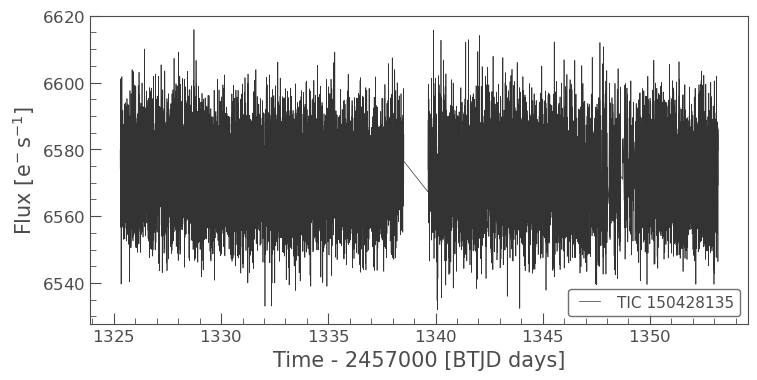

In [4]:
lc = search[0].download()
print(lc.meta["SECTOR"], lc.meta["OBJECT"])
print(lc)
lc.plot();

per-point scatter (2 min): 1656 ppm
30-min binned scatter:     489 ppm
ratio: 3.38   (expected if noise is independent: sqrt(15) = 3.87)
60-min binned scatter:     369 ppm
ratio: 4.49   (expected if noise is independent: sqrt(30) = 5.48)


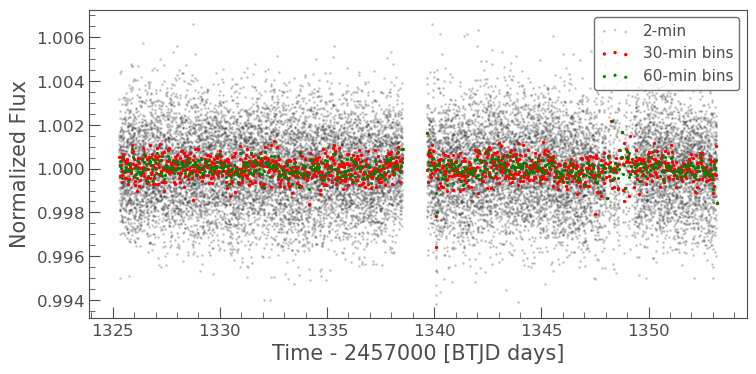

In [6]:
%matplotlib inline
import numpy as np
import astropy.units as u

lc_norm = lc.remove_nans().normalize()

sigma_ppm = np.std(lc_norm.flux.value) * 1e6
print(f"per-point scatter (2 min): {sigma_ppm:.0f} ppm")

binned = lc_norm.bin(time_bin_size=30*u.min).remove_nans()
sigma_bin_ppm = np.std(binned.flux.value) * 1e6
print(f"30-min binned scatter:     {sigma_bin_ppm:.0f} ppm")
print(f"ratio: {sigma_ppm/sigma_bin_ppm:.2f}   (expected if noise is independent: sqrt(15) = 3.87)")

binned2 = lc_norm.bin(time_bin_size=60*u.min).remove_nans()
sigma_bin_ppm2 = np.std(binned2.flux.value) * 1e6
print(f"60-min binned scatter:     {sigma_bin_ppm2:.0f} ppm")
print(f"ratio: {sigma_ppm/sigma_bin_ppm2:.2f}   (expected if noise is independent: sqrt(30) = 5.48)")



ax = lc_norm.scatter(alpha=0.2, label="2-min")
binned.scatter(ax=ax, color="red", s=8, label="30-min bins")
binned2.scatter(ax=ax, color="green", s=6, label="60-min bins");

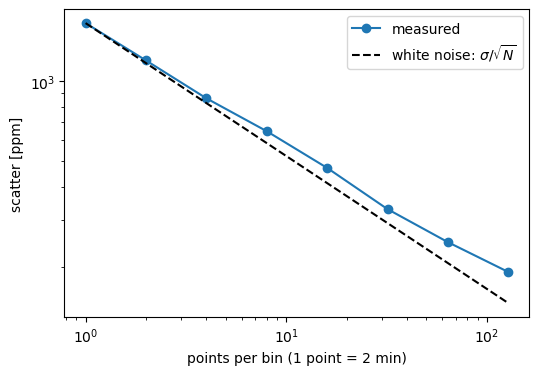

bin of    1 pts (   2 min): measured    1656 ppm, ideal    1656 ppm
bin of    2 pts (   4 min): measured    1198 ppm, ideal    1171 ppm
bin of    4 pts (   8 min): measured     863 ppm, ideal     828 ppm
bin of    8 pts (  16 min): measured     649 ppm, ideal     585 ppm
bin of   16 pts (  32 min): measured     472 ppm, ideal     414 ppm
bin of   32 pts (  64 min): measured     330 ppm, ideal     293 ppm
bin of   64 pts ( 128 min): measured     248 ppm, ideal     207 ppm
bin of  128 pts ( 256 min): measured     192 ppm, ideal     146 ppm


In [7]:
import matplotlib.pyplot as plt

nbin = [1, 2, 4, 8, 16, 32, 64, 128]          # points per bin
rms = []
for m in nbin:
    b = lc_norm.bin(time_bin_size=2*m*u.min).remove_nans() if m > 1 else lc_norm
    rms.append(np.std(b.flux.value) * 1e6)
rms = np.array(rms)
expected = rms[0] / np.sqrt(nbin)

plt.figure(figsize=(6, 4))
plt.loglog(nbin, rms, "o-", label="measured")
plt.loglog(nbin, expected, "k--", label="white noise: $\\sigma/\\sqrt{N}$")
plt.xlabel("points per bin (1 point = 2 min)")
plt.ylabel("scatter [ppm]")
plt.legend()
plt.show()

for m, r, e in zip(nbin, rms, expected):
    print(f"bin of {m:4d} pts ({2*m:4d} min): measured {r:7.0f} ppm, ideal {e:7.0f} ppm")